# Market Risk Modelling: DCC-GJR-GARCH, Value-at-Risk Backtesting and Monte Carlo Simulation

## Objective

This notebook builds an end-to-end market risk framework for an equally weighted portfolio of four US equities: NVDA, MSFT, JNJ and PG.

The portfolio combines two high-growth technology stocks with two defensive stocks from the healthcare and consumer staples sectors, capturing different risk profiles and non-trivial diversification effects.

The objective is to estimate, forecast and validate portfolio risk, and project its future evolution through simulation.

## Data

Daily adjusted closing prices are retrieved from Yahoo Finance using `yfinance` for the period 2010–2025.

- **Asset returns:** Daily log returns expressed in percentage terms.
- **Portfolio returns:** Simple returns with daily rebalancing to fixed weights, ensuring consistency between the portfolio P&L and VaR estimates.
- **Assets:** NVIDIA (NVDA), Microsoft (MSFT), Johnson & Johnson (JNJ) and Procter & Gamble (PG).
- **Portfolio allocation:** Equally weighted, with 25% allocated to each asset.

## Methodology

### 1. Exploratory Data Analysis

Descriptive statistics and diagnostic tests are used to characterize the return distributions and volatility dynamics.

- Descriptive statistics and normality tests using Jarque–Bera.
- ARCH-LM tests to detect conditional heteroskedasticity.
- Ljung–Box tests on squared returns to identify volatility clustering.

### 2. Univariate Volatility Models: GJR-GARCH(1,1)

A GJR-GARCH(1,1) model is fitted to each asset to capture volatility clustering and asymmetric responses to positive and negative shocks, commonly known as the leverage effect.

Model diagnostics are performed on standardized residuals to assess whether significant ARCH effects remain.

### 3. Dynamic Conditional Correlation: DCC-GARCH

Following Engle (2002), the standardized residuals from the univariate models are used to estimate a Dynamic Conditional Correlation (DCC) model.

The resulting time-varying conditional covariance matrix is:

\[
H_t = D_t R_t D_t
\]

where \(D_t\) contains conditional standard deviations and \(R_t\) represents the dynamic correlation matrix.

The model is used to estimate:

- Conditional portfolio volatility.
- Time-varying correlations between assets.
- Portfolio diversification ratios.
- Individual asset contributions to total portfolio risk.

### 4. Out-of-Sample Value-at-Risk Backtesting

The complete model is re-estimated on an expanding window every `REFIT_EVERY` days. Each forecast uses only information available before its forecast date, preventing look-ahead bias.

One-day Value-at-Risk (VaR) is estimated at confidence levels of 95%, 99% and 99.9% under three alternative shock distributions:

- **Normal:** Gaussian quantiles.
- **Student-t:** Quantiles from a Student-t distribution fitted to portfolio shocks.
- **Filtered Historical Simulation (FHS):** Empirical quantiles of standardized portfolio shocks.

Model performance is evaluated using:

- **Kupiec test:** Tests whether the observed breach frequency is consistent with the expected frequency.
- **Christoffersen independence test:** Evaluates whether VaR breaches occur independently.
- **Christoffersen conditional coverage test:** Jointly evaluates breach frequency and independence.

These tests help assess the reliability of VaR estimates across different confidence levels and distributional assumptions.

### 5. Monte Carlo Simulation

Monte Carlo methods are used to simulate one-day portfolio return distributions and 100-day portfolio paths under the full GJR-GARCH-DCC framework.

The simulation estimates:

- One-day portfolio VaR and Expected Shortfall (ES).
- Future portfolio return distributions.
- Multi-day portfolio paths under evolving market conditions.

Both Student-t and normal innovations are considered. Unlike constant-volatility simulations, the model dynamically updates conditional volatilities and correlations along each simulated path.

## Main Parameters

All configuration settings are defined in the first notebook cell, including:

- `TICKERS`: Selected assets.
- `WEIGHTS`: Portfolio allocation.
- Sample period and out-of-sample start date.
- `GARCH_O`: GARCH asymmetry parameter.
- `GARCH_DIST`: Innovation distribution for the GARCH models.
- `REFIT_EVERY`: Model re-estimation frequency.
- `N_SIM`: Number of Monte Carlo simulations.
- `HORIZON`: Simulation horizon.
- `MC_DIST`: Innovation distribution used in Monte Carlo simulations.

## Key Takeaways

- **Heavy tails and volatility clustering:** Asset returns exhibit non-normality and persistent volatility dynamics, supporting the use of GARCH-type models over constant-volatility assumptions.
- **Time-varying diversification:** Correlations change over time, and diversification benefits can weaken during periods of market stress.
- **Unequal risk contributions:** Despite equal portfolio weights, risk is concentrated in NVDA, which contributes more than half of total portfolio risk.
- **Limitations of Gaussian VaR:** Gaussian VaR performs reasonably well at the 95% confidence level but tends to underestimate tail risk at 99% and 99.9%.
- **Fat-tailed alternatives:** Student-t and Filtered Historical Simulation provide alternative approaches to modelling extreme returns and are evaluated directly against the Gaussian benchmark.
- **Dynamic risk forecasting:** Combining GJR-GARCH with DCC-GARCH captures both asymmetric volatility dynamics and changing cross-asset correlations, providing a more comprehensive framework for portfolio risk estimation.

## Disclaimer

This notebook is intended for educational purposes and portfolio risk analysis. It does not constitute investment advice.

# Libraries and Data

In [ ]:
import itertools
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.optimize import minimize
from scipy.special import xlogy
from scipy.stats import norm, chi2
from arch import arch_model
from statsmodels.stats.diagnostic import het_arch, acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf

plt.rcParams.update({"figure.figsize": (12, 5), "axes.grid": True, "grid.alpha": 0.3})
sns.set_style("whitegrid")

# ---------------- Parámetros ----------------
TICKERS = ["NVDA", "MSFT", "JNJ", "PG"]
START, END = "2010-01-01", "2026-01-01"
WEIGHTS = np.array([1/len(TICKERS)] * len(TICKERS))    
PORTFOLIO_VALUE = 1_000_000                     

GARCH_O = 1            
GARCH_DIST = "normal"      

OOS_START = "2016-01-01"   
REFIT_EVERY = 250          
ALPHAS = [0.05, 0.01]      
HS_WINDOW = 500            

MC_DIST = "t"           
N_SIM = 100_000           
HORIZON = 100            
SEED = 42

assert np.isclose(WEIGHTS.sum(), 1.0)
N = len(TICKERS)

In [8]:
data = yf.download(
    TICKERS,
    start=START,
    end=END,
    interval="1d",
    auto_adjust=True
)

prices = data["Close"].copy()
prices = prices[TICKERS].dropna()          # mismo orden que TICKERS y fechas comunes
print(prices.shape, prices.index.min().date(), "->", prices.index.max().date())
prices.tail()

[*********************100%***********************]  4 of 4 completed

(4024, 4) 2010-01-04 -> 2025-12-31


Ticker,NVDA,MSFT,JNJ,PG
Date,,,,
2025-12-24,188.169678,484.943420,204.490875,140.414398
2025-12-26,190.085205,484.635406,204.343262,140.657364
2025-12-29,187.780594,484.029236,204.274368,140.492157
2025-12-30,187.102173,484.406860,203.634659,139.986816
2025-12-31,186.064606,480.571167,203.674011,139.267685


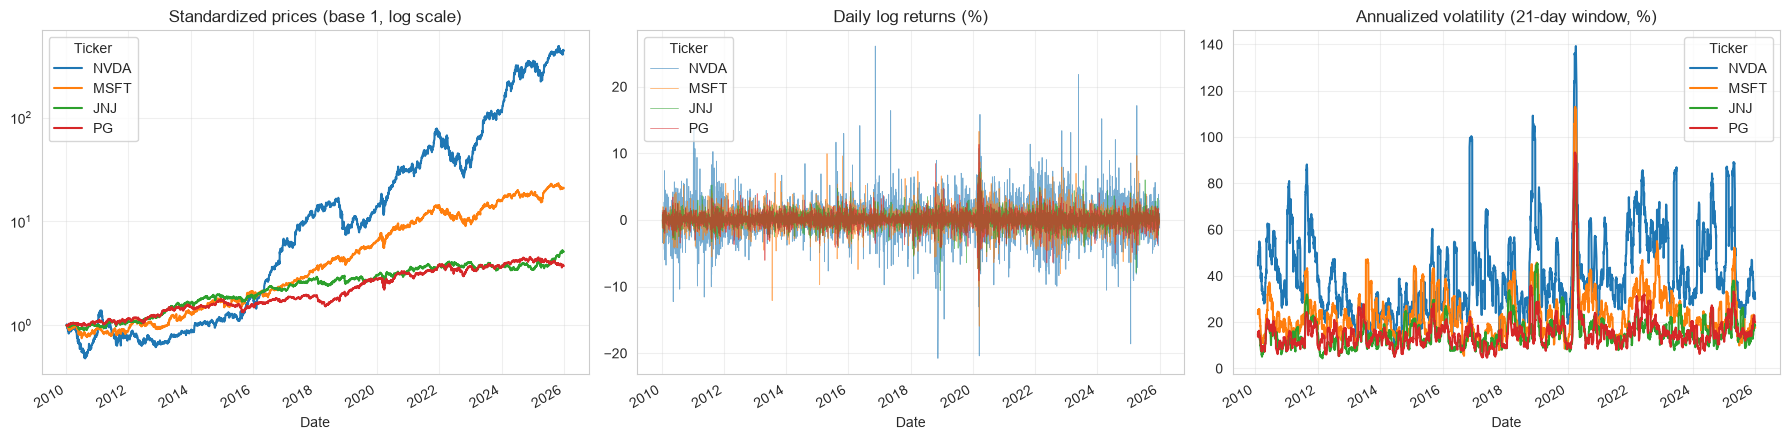

In [ ]:
rets = 100 * np.log(prices / prices.shift(1)).dropna()
port_ret = pd.Series(100 * (np.expm1(rets.values / 100) @ WEIGHTS), index=rets.index, name="cartera")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
(prices / prices.iloc[0]).plot(ax=axes[0], logy=True, title="Standardized prices (base 1, log scale)")
rets.plot(ax=axes[1], alpha=0.6, lw=0.6, title="Daily log returns (%)")
(rets.rolling(21).std() * np.sqrt(252)).plot(ax=axes[2], title="Annualized volatility (21-day window, %)")
plt.tight_layout(); plt.show()

In [10]:
# RETS correlation matrix
rets.corr()

Ticker,NVDA,MSFT,JNJ,PG
Ticker,,,,
NVDA,1.000000,0.570172,0.171230,0.185360
MSFT,0.570172,1.000000,0.352367,0.372036
JNJ,0.171230,0.352367,1.000000,0.529142
PG,0.185360,0.372036,0.529142,1.000000


In [ ]:
def s(vals): return pd.Series(vals, index=rets.columns)

desc = pd.DataFrame({
    "Daily Mean Return %":          rets.mean(),
    "Annualized Volatility %":      rets.std() * np.sqrt(252),
    "Skewness":                     rets.skew(),
    "Excess Kurtosis":              rets.kurt(),
    "Jarque-Bera p-value":          s([
        stats.jarque_bera(rets[c])[1]
        for c in rets
    ]),
    "ARCH-LM p-value (10 lags)":    s([
        het_arch(
            rets[c] - rets[c].mean(),
            nlags=10
        )[1]
        for c in rets
    ]),
    "Ljung-Box p-value on r² (10)": s([
        acorr_ljungbox(
            rets[c] ** 2,
            lags=[10]
        )["lb_pvalue"].iloc[0]
        for c in rets
    ]),
}).round(4)

display(desc)

,Daily Mean Return %,Annualized Volatility %,Skewness,Excess Kurtosis,Jarque-Bera p-value,ARCH-LM p-value (10 lags),Ljung-Box p-value on r² (10)
Ticker,,,,,,,
NVDA,0.1513,45.4174,0.1722,6.8737,0.0,0.0,0.0
MSFT,0.0756,25.4804,-0.1430,8.0703,0.0,0.0,0.0
JNJ,0.0406,16.9165,-0.3312,9.4008,0.0,0.0,0.0
PG,0.0327,17.2070,-0.1085,10.5686,0.0,0.0,0.0


The descriptive statistics show clear differences in risk across the four assets, with NVDA exhibiting the highest annualized volatility (45.4%) and daily mean return (0.15%). All assets display positive excess kurtosis and highly significant Jarque-Bera tests, indicating non-normal return distributions with heavy tails. The ARCH-LM and Ljung-Box tests are significant for all assets, providing strong evidence of volatility clustering and conditional heteroskedasticity, supporting the use of GARCH-type models.

# DCC

## DCC-GARCH (Engle, 2002)

With $z_t = \varepsilon_t / \sigma_t$ (standardized residuals from Step 1):

$$
Q_t = (1-a-b)\,\bar Q + a\,z_{t-1}z_{t-1}' + b\,Q_{t-1},
\qquad
R_t = \mathrm{diag}(Q_t)^{-1/2}\,Q_t\,\mathrm{diag}(Q_t)^{-1/2}
$$

$$
H_t = D_t R_t D_t,
\qquad
D_t = \mathrm{diag}(\sigma_{1,t},\dots,\sigma_{N,t})
$$

The parameters $(a,b)$ are estimated by quasi-maximum likelihood for the correlation component, subject to $a,b\geq 0$ and $a+b<1$:

$$
\mathcal{L}_C =
-\frac{1}{2}\sum_t
\left(
\ln|R_t| +
z_t'R_t^{-1}z_t -
z_t'z_t
\right)
$$


In [12]:
def fit_garch(y, dist=GARCH_DIST):
    am = arch_model(
        y,
        mean="Constant",
        vol="GARCH",
        p=1,
        o=GARCH_O,
        q=1,
        dist=dist,
        rescale=False
    )
    return am, am.fit(disp="off")


# Fit GARCH(1,1) / GJR-GARCH(1,1) for each asset
uni = {
    c: fit_garch(rets[c])[1]
    for c in TICKERS
}


# Estimated parameters
par_tbl = pd.DataFrame({
    c: r.params
    for c, r in uni.items()
}).T

# For GJR-GARCH, the usual persistence measure under symmetric innovations
# is alpha + beta + gamma/2. For standard GARCH, gamma is absent.
par_tbl["Persistence"] = (
    par_tbl["alpha[1]"]
    + par_tbl["beta[1]"]
    + 0.5 * par_tbl.get("gamma[1]", 0.0)
)

display(par_tbl.round(4))


# Diagnostic tests on standardized residuals
diag = pd.DataFrame({
    c: {
        "Ljung-Box(10) z² p-value":
            acorr_ljungbox(
                r.std_resid.dropna() ** 2,
                lags=[10]
            )["lb_pvalue"].iloc[0],

        "ARCH-LM(10) p-value":
            het_arch(
                r.std_resid.dropna(),
                nlags=10
            )[1]
    }
    for c, r in uni.items()
}).T.round(4)

display(diag)


# Standardized residuals for DCC-GARCH
std_resid = pd.DataFrame({
    c: r.std_resid
    for c, r in uni.items()
}).dropna()


,mu,omega,alpha[1],gamma[1],beta[1],Persistence
NVDA,0.1726,0.3201,0.0537,0.0850,0.8703,0.9664
MSFT,0.0732,0.0863,0.0145,0.0820,0.9092,0.9647
JNJ,0.0372,0.0479,0.0332,0.0690,0.8879,0.9556
PG,0.0252,0.0478,0.0250,0.0824,0.8886,0.9548


,Ljung-Box(10) z² p-value,ARCH-LM(10) p-value
NVDA,0.9201,0.9188
MSFT,0.9481,0.9514
JNJ,0.9998,0.9998
PG,0.8884,0.8975


The GARCH(1,1) diagnostics indicate that the standardized residuals no longer exhibit significant volatility dependence. Both the Ljung-Box and ARCH-LM tests produce high p-values for all four assets, providing no evidence of remaining autocorrelation or ARCH effects. This suggests that the GARCH(1,1) models adequately capture the conditional volatility dynamics of the individual assets, supporting their use as the first stage of the subsequent DCC-GARCH model.

In [13]:
def dcc_recursion(z, a, b, Qbar):
    """
    DCC(1,1) recursion:
    Q_t = (1-a-b)Qbar + a z_{t-1}z'_{t-1} + b Q_{t-1}
    """
    T, n = z.shape

    Q = np.empty((T, n, n))
    Q[0] = Qbar

    zz = z[:, :, None] * z[:, None, :]

    for t in range(1, T):
        Q[t] = (
            (1 - a - b) * Qbar
            + a * zz[t - 1]
            + b * Q[t - 1]
        )

    d = 1.0 / np.sqrt(np.einsum("tii->ti", Q))

    R = Q * d[:, :, None] * d[:, None, :]

    return Q, R


def dcc_negloglik(params, z, Qbar):
    a, b = params

    if a < 0 or b < 0 or a + b >= 0.9999:
        return 1e10

    _, R = dcc_recursion(z, a, b, Qbar)

    _, logdet = np.linalg.slogdet(R)

    Rinv_z = np.linalg.solve(
        R,
        z[:, :, None]
    )[:, :, 0]

    quad = np.einsum("ti,ti->t", z, Rinv_z)
    zz = np.einsum("ti,ti->t", z, z)

    return 0.5 * np.sum(
        logdet[1:] + quad[1:] - zz[1:]
    )


def fit_dcc(z, x0=(0.02, 0.95)):

    Qbar = z.T @ z / len(z)

    res = minimize(
        dcc_negloglik,
        x0=x0,
        args=(z, Qbar),
        method="SLSQP",
        bounds=[
            (1e-6, 0.5),
            (1e-6, 0.9999)
        ],
        constraints=[
            {
                "type": "ineq",
                "fun": lambda p: 0.9998 - p[0] - p[1]
            }
        ]
    )

    return res.x[0], res.x[1], Qbar


def cov_from_dcc(R, sig):
    """
    H_t = D_t R_t D_t
    """
    return (
        R
        * sig[:, :, None]
        * sig[:, None, :]
    )

In [14]:
z_df = pd.DataFrame({
    c: r.std_resid
    for c, r in uni.items()
}).dropna()

sig_df = pd.DataFrame({
    c: uni[c].conditional_volatility
    for c in TICKERS
}).loc[z_df.index]

z = z_df.values
sig = sig_df.values

a_hat, b_hat, Qbar = fit_dcc(z)

Q, R = dcc_recursion(
    z,
    a_hat,
    b_hat,
    Qbar
)

H = cov_from_dcc(R, sig)

print(
    f"DCC(1,1): a = {a_hat:.4f}, "
    f"b = {b_hat:.4f}, "
    f"a+b = {a_hat + b_hat:.4f}"
)

print("Unconditional correlation matrix:")

display(
    pd.DataFrame(
        Qbar,
        index=TICKERS,
        columns=TICKERS
    ).round(3)
)

DCC(1,1): a = 0.0143, b = 0.9766, a+b = 0.9909
Unconditional correlation matrix:


,NVDA,MSFT,JNJ,PG
NVDA,0.999,0.496,0.110,0.123
MSFT,0.496,1.000,0.260,0.278
JNJ,0.110,0.260,1.000,0.435
PG,0.123,0.278,0.435,1.000


The estimated DCC-GARCH parameters, a = 0.0144 and b = 0.9769, indicate a highly persistent dynamic correlation structure, with a + b = 0.9913, meaning that shocks to correlations tend to decay slowly over time. The unconditional correlation matrix shows that NVDA and MSFT have the strongest relationship (0.498), while JNJ and PG also exhibit a relatively high correlation (0.432), consistent with their defensive characteristics. In contrast, the correlations between the technology stocks and the defensive assets are considerably lower, particularly NVDA–JNJ (0.112) and NVDA–PG (0.122). This suggests that combining these four assets provides meaningful diversification benefits, although the relatively high correlation between NVDA and MSFT can limit diversification within the technology component of the portfolio.

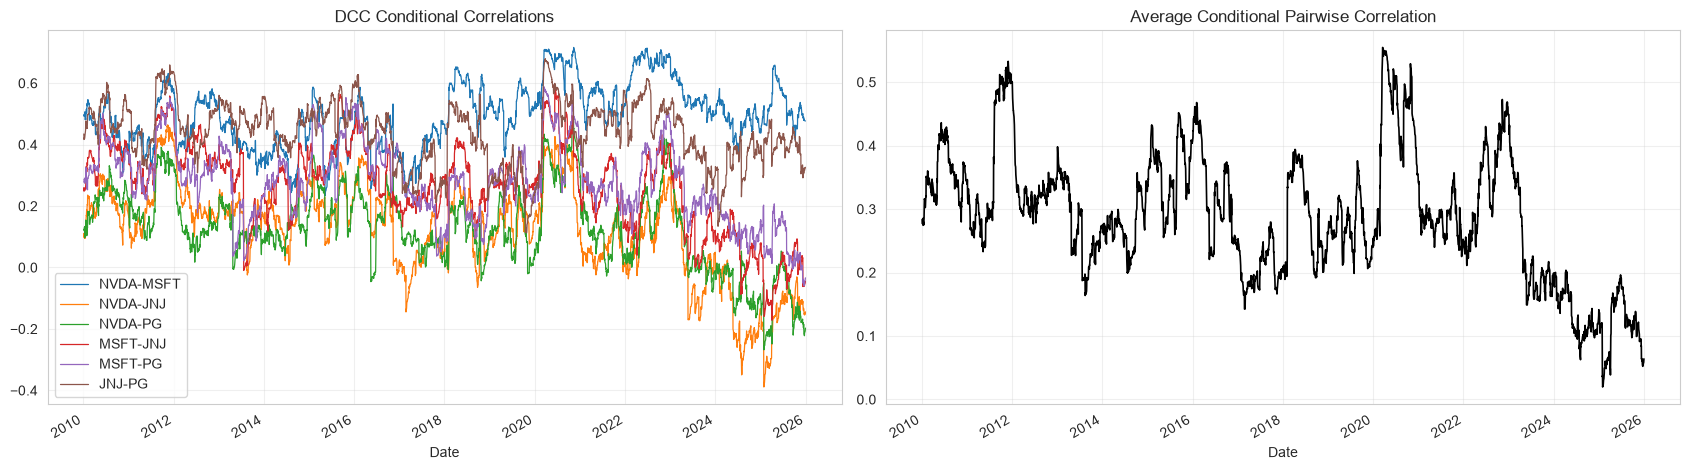

In [15]:
pairs = list(itertools.combinations(range(N), 2))

corr_dyn = pd.DataFrame(
    {
        f"{TICKERS[i]}-{TICKERS[j]}": R[:, i, j]
        for i, j in pairs
    },
    index=z_df.index
)

fig, axes = plt.subplots(1, 2, figsize=(17, 4.8))

corr_dyn.plot(
    ax=axes[0],
    lw=0.9,
    title="DCC Conditional Correlations"
)

corr_dyn.mean(axis=1).rename(
    "Average Pairwise Correlation"
).plot(
    ax=axes[1],
    color="k",
    lw=1.2,
    title="Average Conditional Pairwise Correlation"
)

plt.tight_layout()
plt.show()

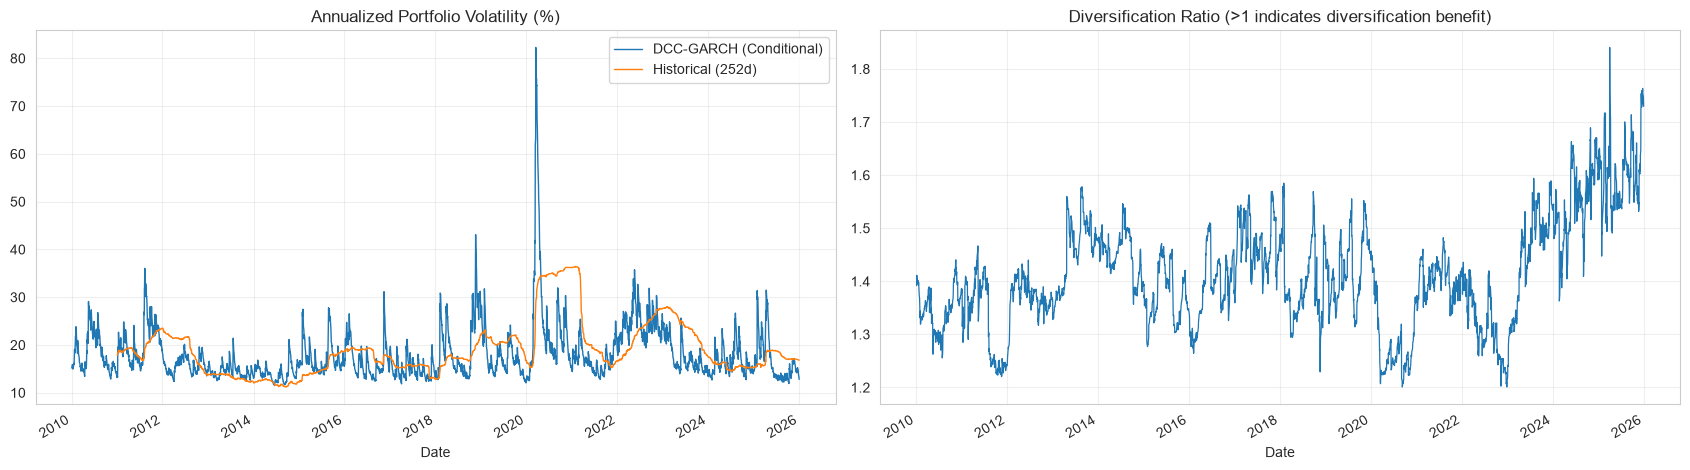

Date: 2025-12-31 | DCC Portfolio Daily Volatility: 0.806% | Annualized: 12.79%


,Weight,Conditional Daily Volatility (%),Risk Contribution (daily volatility points),Relative Risk Contribution
NVDA,0.25,2.2420,0.4337,0.5383
MSFT,0.25,1.2715,0.2230,0.2767
JNJ,0.25,0.9882,0.0734,0.0911
PG,0.25,1.0724,0.0756,0.0939


In [16]:
# Portfolio volatility: DCC-GARCH vs. rolling historical volatility (252d)

sigma_p_dcc = np.sqrt(
    np.einsum("i,tij,j->t", WEIGHTS, H, WEIGHTS)
)

vol_dcc = pd.Series(
    sigma_p_dcc,
    index=z_df.index
) * np.sqrt(252)

vol_hist = (
    port_ret.rolling(252).std()
    * np.sqrt(252)
)


# Diversification ratio:
# sum(w_i * sigma_i) / portfolio volatility

div_ratio = pd.Series(
    (sig_df.values @ WEIGHTS) / sigma_p_dcc,
    index=z_df.index
)


fig, axes = plt.subplots(1, 2, figsize=(17, 4.8))

vol_dcc.plot(
    ax=axes[0],
    label="DCC-GARCH (Conditional)",
    lw=1
)

vol_hist.plot(
    ax=axes[0],
    label="Historical (252d)",
    lw=1
)

axes[0].set_title("Annualized Portfolio Volatility (%)")
axes[0].legend()


div_ratio.plot(
    ax=axes[1],
    lw=0.9,
    title="Diversification Ratio (>1 indicates diversification benefit)"
)

plt.tight_layout()
plt.show()


# Risk contribution at the latest date:
# RC_i = w_i * (H w)_i / sigma_p

H_T = H[-1]
sp_T = sigma_p_dcc[-1]

rc = (
    WEIGHTS
    * (H_T @ WEIGHTS)
    / sp_T
)

rc_df = pd.DataFrame(
    {
        "Weight": WEIGHTS,
        "Conditional Daily Volatility (%)":
            sig_df.iloc[-1].values,
        "Risk Contribution (daily volatility points)": rc,
        "Relative Risk Contribution":
            rc / sp_T,
    },
    index=TICKERS
).round(4)


print(
    f"Date: {z_df.index[-1].date()} | "
    f"DCC Portfolio Daily Volatility: {sp_T:.3f}% | "
    f"Annualized: {sp_T * np.sqrt(252):.2f}%"
)

display(rc_df)

NVDA is the main source of risk, with a conditional daily volatility of 2.2572% and a 55.72% relative risk contribution, reflecting its higher volatility compared with the other holdings. MSFT contributes 25.00% of total portfolio risk, while the more defensive stocks JNJ and PG account for only 9.17% and 10.11%, respectively. Overall, the results show that although the portfolio is equally weighted, its risk is not equally distributed, with NVDA driving more than half of the portfolio's total risk.

This analysis evaluates a portfolio composed of NVDA, MSFT, JNJ, and PG, combining high-growth technology stocks with defensive healthcare and consumer-staples companies. The DCC-GARCH conditional volatility highlights periods of increased market risk, particularly around major market shocks, while the historical volatility provides a smoother benchmark based on past returns. The diversification ratio remains consistently above 1, indicating that combining these assets provides a meaningful diversification benefit, with the ratio reaching higher levels in more recent periods as the portfolio benefits from the different risk and return dynamics of its constituents.

# VaR backtesting (out-of-sample)

Expanding window, re-estimation every `REFIT_EVERY` days. Three versions of the VaR share the same DCC-GJR-GARCH volatility forecast and differ only in the shock quantile: **Normal**, **Student-t** and **Filtered Historical Simulation (FHS)**. Tests: Kupiec (coverage) and Christoffersen (independence and conditional coverage).

In [ ]:
oos_dates = rets.index[rets.index >= pd.Timestamp(OOS_START)]

if len(oos_dates) == 0:
    raise ValueError("OOS_START is after the last available return date.")

oos_sigma = pd.Series(index=oos_dates, dtype=float)
oos_mu = pd.Series(index=oos_dates, dtype=float)

CONF_LEVELS = [0.95, 0.99, 0.999]
def lab(conf):
    # int(0.999*100) == 99 would collide with 0.99 -> use a safe label
    return f"{conf * 100:g}"          # "95", "99", "99.9"

q_fhs_blk, q_t_blk = {}, {}
oos_q_fhs = pd.DataFrame(index=oos_dates, columns=CONF_LEVELS, dtype=float)
oos_q_t = pd.DataFrame(index=oos_dates, columns=CONF_LEVELS, dtype=float)
nu_hist = []
oos_R = np.full((len(oos_dates), N, N), np.nan)

for block_start in range(0, len(oos_dates), REFIT_EVERY):

    block_dates = oos_dates[
        block_start:block_start + REFIT_EVERY
    ]

    # Expanding training sample: only dates strictly before the OOS block.
    train_end = block_dates[0] - pd.Timedelta(days=1)
    train_rets = rets.loc[:train_end]

    if len(train_rets) < 500:
        raise ValueError(
            "Not enough observations in the initial training sample."
        )

    # Refit the univariate volatility models using training data only.
    block_uni = {
        c: fit_garch(train_rets[c])[1]
        for c in TICKERS
    }

    # Training standardized residuals used to estimate the DCC parameters.
    block_z_df = pd.DataFrame({
        c: block_uni[c].std_resid
        for c in TICKERS
    }).dropna()

    block_z = block_z_df.values

    block_a, block_b, block_Qbar = fit_dcc(block_z)

    # Last observed state available at the beginning of the OOS block.
    # Q_t must be the filtered DCC matrix at the end of training (not Qbar),
    # otherwise the first forecasts ignore the accumulated correlation dynamics.
    Q_train, _ = dcc_recursion(block_z, block_a, block_b, block_Qbar)
    prev_z = block_z[-1].copy()
    prev_Q = Q_train[-1].copy()

    # ---- Standardized PORTFOLIO shocks in the training sample (for t and FHS VaR)
    sig_tr = np.column_stack([
        block_uni[c].conditional_volatility.loc[block_z_df.index] for c in TICKERS
    ])
    _, R_train = dcc_recursion(block_z, block_a, block_b, block_Qbar)
    sigma_p_tr = np.sqrt(np.einsum("i,tij,j->t", WEIGHTS, cov_from_dcc(R_train, sig_tr), WEIGHTS))
    mu_p_tr = WEIGHTS @ np.array([block_uni[c].params["mu"] for c in TICKERS])
    q_tr = (port_ret.loc[block_z_df.index].values - mu_p_tr) / sigma_p_tr

    nu_t, _, scale_t = stats.t.fit(q_tr, floc=0)      # Student-t fitted to portfolio shocks
    nu_hist.append(nu_t)
    for conf in CONF_LEVELS:
        q_fhs_blk[conf] = np.quantile(q_tr, 1 - conf)  # Filtered Historical Simulation
        q_t_blk[conf] = stats.t.ppf(1 - conf, nu_t, scale=scale_t)

    prev_sigma2 = np.array([
        block_uni[c].conditional_volatility.iloc[-1] ** 2
        for c in TICKERS
    ])

    prev_eps = np.array([
        block_uni[c].resid.iloc[-1]
        for c in TICKERS
    ])

    mu = np.array([
        block_uni[c].params["mu"]
        for c in TICKERS
    ])

    omega = np.array([
        block_uni[c].params["omega"]
        for c in TICKERS
    ])

    alpha = np.array([
        block_uni[c].params["alpha[1]"]
        for c in TICKERS
    ])

    beta = np.array([
        block_uni[c].params["beta[1]"]
        for c in TICKERS
    ])

    gamma = np.array([
        block_uni[c].params.get("gamma[1]", 0.0)
        for c in TICKERS
    ])

    for date in block_dates:

        # One-step-ahead GARCH/GJR-GARCH variance forecast.
        leverage = (prev_eps < 0).astype(float)

        sigma2_t = (
            omega
            + alpha * prev_eps**2
            + gamma * leverage * prev_eps**2
            + beta * prev_sigma2
        )

        sigma_t = np.sqrt(np.maximum(sigma2_t, 1e-12))

        # One-step-ahead DCC correlation forecast.
        Q_t = (
            (1 - block_a - block_b) * block_Qbar
            + block_a * np.outer(prev_z, prev_z)
            + block_b * prev_Q
        )

        d_t = 1.0 / np.sqrt(np.maximum(np.diag(Q_t), 1e-12))
        R_t = Q_t * d_t[:, None] * d_t[None, :]

        # Portfolio conditional volatility from H_t = D_t R_t D_t.
        H_t = (
            R_t
            * sigma_t[:, None]
            * sigma_t[None, :]
        )

        sigma_p_t = np.sqrt(
            WEIGHTS @ H_t @ WEIGHTS
        )

        oos_sigma.loc[date] = sigma_p_t
        oos_mu.loc[date] = WEIGHTS @ mu      # conditional mean of the portfolio
        for conf in CONF_LEVELS:
            oos_q_fhs.loc[date, conf] = q_fhs_blk[conf]
            oos_q_t.loc[date, conf] = q_t_blk[conf]

        out_idx = oos_dates.get_loc(date)
        oos_R[out_idx] = R_t

        # Observe today's return and update the state for tomorrow.
        eps_t = rets.loc[date].values - mu
        z_t = eps_t / sigma_t

        prev_eps = eps_t
        prev_sigma2 = sigma2_t
        prev_z = z_t
        prev_Q = Q_t


sigma_p = oos_sigma


MODELS = {"Normal": "", "Student-t": "_t", "FHS": "_FHS"}

var_df = pd.DataFrame(index=oos_sigma.index)

for conf in CONF_LEVELS:
    var_df[f"VaR_{lab(conf)}%"]      = -(oos_mu + norm.ppf(1 - conf) * sigma_p)
    var_df[f"VaR_{lab(conf)}%_t"]    = -(oos_mu + oos_q_t[conf] * sigma_p)
    var_df[f"VaR_{lab(conf)}%_FHS"]  = -(oos_mu + oos_q_fhs[conf] * sigma_p)

print("Student-t degrees of freedom per re-fit:", np.round(nu_hist, 2))
display(var_df.tail().round(3))


Student-t degrees of freedom per re-fit: [6.04 5.5  4.98 5.35 5.34 5.34 5.59 5.78 5.94 5.85 5.66]


,VaR_95%,VaR_95%_t,VaR_95%_FHS,VaR_99%,VaR_99%_t,VaR_99%_FHS,VaR_99.9%,VaR_99.9%_t,VaR_99.9%_FHS
Date,,,,,,,,,
2025-12-24,1.398,1.320,1.391,2.009,2.204,2.203,2.693,3.766,3.612
2025-12-26,1.354,1.279,1.348,1.947,2.137,2.136,2.611,3.651,3.502
2025-12-29,1.311,1.239,1.305,1.887,2.071,2.070,2.532,3.541,3.397
2025-12-30,1.290,1.219,1.285,1.857,2.039,2.038,2.492,3.486,3.344
2025-12-31,1.256,1.187,1.251,1.809,1.986,1.985,2.428,3.398,3.259


In [20]:
risk_df = pd.concat(
    [
        port_ret.rename("Portfolio Return"),
        var_df
    ],
    axis=1
).loc[oos_dates].dropna()


In [21]:
rows = []

for model, suf in MODELS.items():
    for conf in CONF_LEVELS:
        col = f"VaR_{lab(conf)}%{suf}"
        brc = f"Breach_{lab(conf)}%{suf}"
        risk_df[brc] = risk_df["Portfolio Return"] < -risk_df[col]

        rows.append({
            "Model": model,
            "Confidence Level": f"{lab(conf)}%",
            "Expected Breach Rate": 1 - conf,
            "Observed Breach Rate": risk_df[brc].mean(),
            "Number of Breaches": int(risk_df[brc].sum()),
            "Expected Breaches": (1 - conf) * len(risk_df),
        })

breaches = pd.DataFrame(rows)
display(breaches.round(4))


,Model,Confidence Level,Expected Breach Rate,Observed Breach Rate,Number of Breaches,Expected Breaches
0,Normal,95%,0.050,0.0533,134,125.700
1,Normal,99%,0.010,0.0159,40,25.140
2,Normal,99.9%,0.001,0.0048,12,2.514
3,Student-t,95%,0.050,0.0625,157,125.700
4,Student-t,99%,0.010,0.0119,30,25.140
5,Student-t,99.9%,0.001,0.0012,3,2.514
6,FHS,95%,0.050,0.0529,133,125.700
7,FHS,99%,0.010,0.0119,30,25.140
8,FHS,99.9%,0.001,0.0016,4,2.514


In [22]:
def kupiec_pof_test(returns, var, confidence):
    """
    Kupiec Proportion of Failures (POF) test.

    returns: portfolio returns
    var: positive VaR series
    confidence: confidence level, e.g. 0.99
    """

    exceptions = returns < -var

    x = exceptions.sum()
    T = len(exceptions)

    p = 1 - confidence
    phat = x / T

    # Avoid log(0)
    eps = 1e-12

    phat_safe = np.clip(phat, eps, 1 - eps)

    log_likelihood_null = (
        (T - x) * np.log(1 - p)
        + x * np.log(p)
    )

    log_likelihood_alt = (
        (T - x) * np.log(1 - phat_safe)
        + x * np.log(phat_safe)
    )

    LR = -2 * (
        log_likelihood_null
        - log_likelihood_alt
    )

    p_value = 1 - chi2.cdf(LR, df=1)

    return {
        "Exceptions": x,
        "Observations": T,
        "Expected Rate": p,
        "Observed Rate": phat,
        "Kupiec LR": LR,
        "p-value": p_value
    }

def christoffersen_tests(exceptions, confidence):
    """
    Christoffersen (1998) independence and conditional coverage tests.
    LR_ind: are breaches independent (no clustering)?  ~ chi2(1)
    LR_cc = LR_pof + LR_ind                            ~ chi2(2)
    """
    I = np.asarray(exceptions, dtype=int)
    n00 = np.sum((I[:-1] == 0) & (I[1:] == 0))
    n01 = np.sum((I[:-1] == 0) & (I[1:] == 1))
    n10 = np.sum((I[:-1] == 1) & (I[1:] == 0))
    n11 = np.sum((I[:-1] == 1) & (I[1:] == 1))

    pi01 = n01 / max(n00 + n01, 1)
    pi11 = n11 / max(n10 + n11, 1)
    pi = (n01 + n11) / (n00 + n01 + n10 + n11)

    ll0 = xlogy(n00 + n10, 1 - pi) + xlogy(n01 + n11, pi)
    ll1 = (xlogy(n00, 1 - pi01) + xlogy(n01, pi01)
           + xlogy(n10, 1 - pi11) + xlogy(n11, pi11))

    LR_ind = max(-2 * (ll0 - ll1), 0.0)

    p = 1 - confidence
    x, T = I.sum(), len(I)
    ll_null = xlogy(T - x, 1 - p) + xlogy(x, p)
    ll_alt = xlogy(T - x, 1 - x / T) + xlogy(x, x / T)
    LR_pof = max(-2 * (ll_null - ll_alt), 0.0)

    LR_cc = LR_pof + LR_ind

    return {
        "LR ind": LR_ind,
        "p ind": 1 - chi2.cdf(LR_ind, df=1),
        "LR cc": LR_cc,
        "p cc": 1 - chi2.cdf(LR_cc, df=2),
    }


In [23]:
test_rows = []

for model, suf in MODELS.items():
    for conf in CONF_LEVELS:
        col = f"VaR_{lab(conf)}%{suf}"

        k = kupiec_pof_test(risk_df["Portfolio Return"], risk_df[col], conf)
        exc = risk_df["Portfolio Return"] < -risk_df[col]
        c = christoffersen_tests(exc, conf)

        test_rows.append({
            "Model": model,
            "Confidence Level": f"{lab(conf)}%",
            "Exceptions": k["Exceptions"],
            "Expected": round((1 - conf) * k["Observations"], 1),
            "Observed Rate": k["Observed Rate"],
            "Kupiec p (coverage)": k["p-value"],
            "Christoffersen p (independence)": c["p ind"],
            "Christoffersen p (cond. coverage)": c["p cc"],
        })

kupiec_df = pd.DataFrame(test_rows)
display(kupiec_df.round(4))

# Reading guide: p > 0.05 -> do not reject the model.
# Kupiec = correct number of breaches; independence = breaches not clustered;
# conditional coverage = both jointly.


,Model,Confidence Level,Exceptions,Expected,Observed Rate,Kupiec p (coverage),Christoffersen p (independence),Christoffersen p (cond. coverage)
0,Normal,95%,134,125.7,0.0533,0.4522,0.2743,0.4147
1,Normal,99%,40,25.1,0.0159,0.0061,0.6687,0.0212
2,Normal,99.9%,12,2.5,0.0048,0.0000,0.7344,0.0001
3,Student-t,95%,157,125.7,0.0625,0.0057,0.9311,0.0220
4,Student-t,99%,30,25.1,0.0119,0.3445,0.3945,0.4452
5,Student-t,99.9%,3,2.5,0.0012,0.7661,0.9325,0.9533
6,FHS,95%,133,125.7,0.0529,0.5079,0.2551,0.4203
7,FHS,99%,30,25.1,0.0119,0.3445,0.3945,0.4452
8,FHS,99.9%,4,2.5,0.0016,0.3883,0.9101,0.6849


**How to read the table:** the Normal VaR typically passes at 95% but fails at 99% and 99.9%, because Gaussian tails are too thin. The Student-t and FHS versions should reduce the excess of breaches in the extreme tails. If the independence p-value is low, breaches are clustered (e.g. 2020) and the issue is volatility dynamics, not only tail shape.

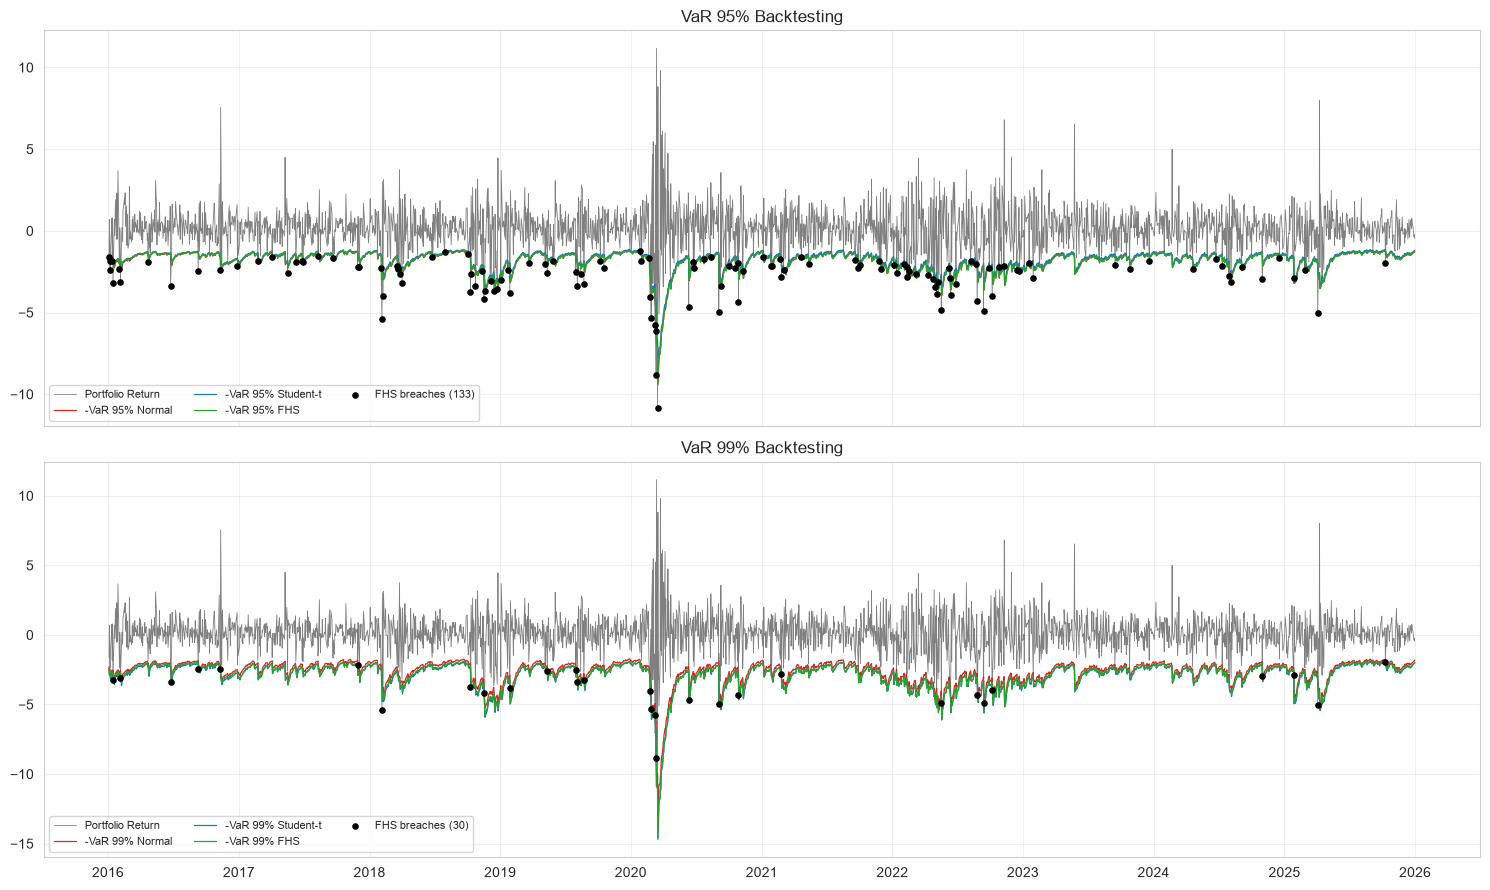

In [24]:
PLOT_MODEL = "FHS"          # model whose breaches are marked: "Normal", "Student-t" or "FHS"
plot_suf = MODELS[PLOT_MODEL]

fig, axes = plt.subplots(2, 1, figsize=(15, 9), sharex=True)

for ax, cl in zip(axes, ["95", "99"]):

    ax.plot(risk_df.index, risk_df["Portfolio Return"],
            color="grey", lw=0.6, label="Portfolio Return")

    for model, suf, colr in [("Normal", "", "tab:red"),
                             ("Student-t", "_t", "tab:blue"),
                             ("FHS", "_FHS", "tab:green")]:
        ax.plot(risk_df.index, -risk_df[f"VaR_{cl}%{suf}"],
                color=colr, lw=0.9, label=f"-VaR {cl}% {model}")

    viol = risk_df[f"Breach_{cl}%{plot_suf}"]
    ax.scatter(risk_df.index[viol], risk_df.loc[viol, "Portfolio Return"],
               color="k", s=14, zorder=5,
               label=f"{PLOT_MODEL} breaches ({viol.sum()})")

    ax.set_title(f"VaR {cl}% Backtesting")
    ax.legend(loc="lower left", ncol=3, fontsize=8)

plt.tight_layout()
plt.show()


# Montecarlo

In [ ]:
rng = np.random.default_rng(SEED)

# Full-sample GJR-GARCH / DCC parameters
mu_f    = np.array([uni[c].params["mu"] for c in TICKERS])
omega_f = np.array([uni[c].params["omega"] for c in TICKERS])
alpha_f = np.array([uni[c].params["alpha[1]"] for c in TICKERS])
beta_f  = np.array([uni[c].params["beta[1]"] for c in TICKERS])
gamma_f = np.array([uni[c].params.get("gamma[1]", 0.0) for c in TICKERS])

# State at the last observed date T
eps_T  = np.array([uni[c].resid.iloc[-1] for c in TICKERS])
sig2_T = sig_df.iloc[-1].values ** 2
z_T    = z_df.values[-1]
Q_T    = Q[-1]

# One-step-ahead forecast (T+1): the simulated day is tomorrow, so we need
# sigma_{T+1} and R_{T+1}, NOT the filtered sigma_T and R_T.
sig2_next = omega_f + (alpha_f + gamma_f * (eps_T < 0)) * eps_T**2 + beta_f * sig2_T
sigma_next = np.sqrt(sig2_next)

Q_next = (1 - a_hat - b_hat) * Qbar + a_hat * np.outer(z_T, z_T) + b_hat * Q_T
d_next = 1.0 / np.sqrt(np.diag(Q_next))
R_next = Q_next * d_next[:, None] * d_next[None, :]

# Conditional covariance matrix of daily log returns (%^2)
H_T = R_next * sigma_next[:, None] * sigma_next[None, :]

# ------------------------------------------------------------
# Shock distribution: multivariate Student-t (unit variance) or normal
# ------------------------------------------------------------
if MC_DIST == "t":
    q_full = (
        (port_ret.loc[z_df.index].values - WEIGHTS @ mu_f) / sigma_p_dcc
    )
    nu_mc, _, _ = stats.t.fit(q_full, floc=0)
    nu_mc = float(np.clip(nu_mc, 2.5, 100))
    print(f"Student-t degrees of freedom used in Monte Carlo: {nu_mc:.2f}")
else:
    nu_mc = None


def draw_scale(rng, size, nu):
    """Common mixing factor so that Lc@u*scale ~ multivariate t with unit variance."""
    if nu is None:
        return np.ones(size)
    return np.sqrt((nu - 2) / nu) * np.sqrt(nu / rng.chisquare(nu, size=size))


# Simulate daily log returns: r = mu + sigma * (L u) * scale,  corr(L L') = R_next
L_next = np.linalg.cholesky(R_next)
u = rng.standard_normal((N_SIM, N))
scale = draw_scale(rng, (N_SIM, 1), nu_mc)
sim_log_returns = mu_f + sigma_next * (u @ L_next.T) * scale

# Portfolio SIMPLE return: convert each asset to simple return first, then weight
# (the weighted sum of log returns is not the portfolio log return).
sim_port_returns = 100 * (np.expm1(sim_log_returns / 100) @ WEIGHTS)


Student-t degrees of freedom used in Monte Carlo: 5.65


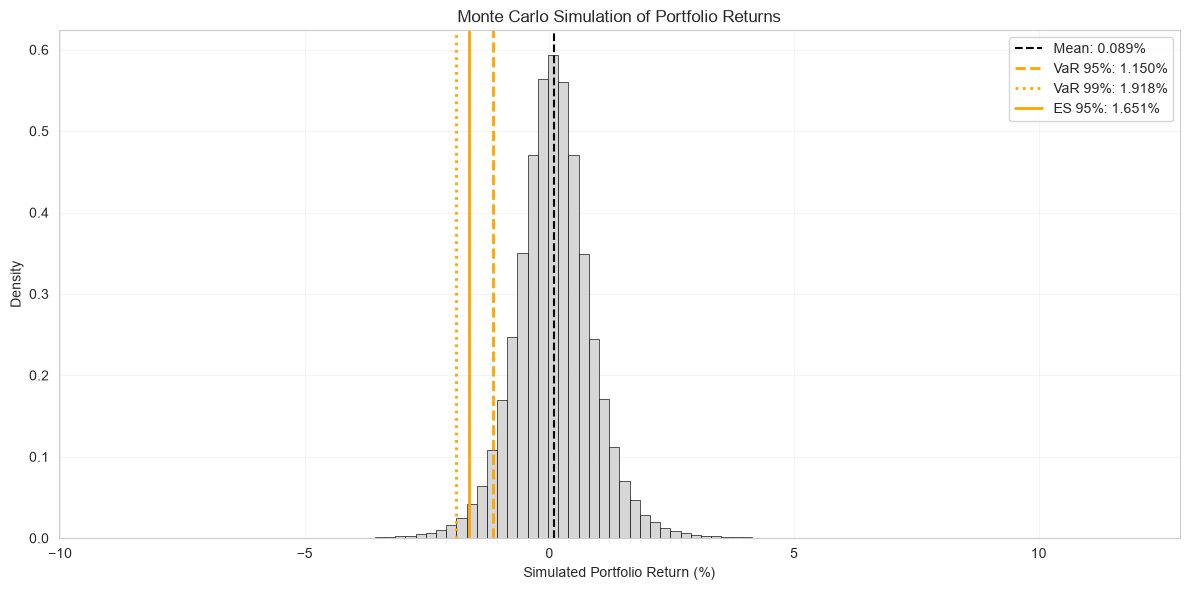

In [ ]:
alpha_95 = 0.05
alpha_99 = 0.01

# VaR: positive values represent loss magnitudes
q_95 = np.quantile(sim_port_returns, alpha_95)
q_99 = np.quantile(sim_port_returns, alpha_99)

VaR_95 = -q_95
VaR_99 = -q_99

# Expected Shortfall: average loss in the tail
ES_95 = -sim_port_returns[sim_port_returns <= q_95].mean()
ES_99 = -sim_port_returns[sim_port_returns <= q_99].mean()

mean_sim = sim_port_returns.mean()

# ============================================================
# Histogram
# ============================================================

fig, ax = plt.subplots(figsize=(12, 6))

ax.hist(
    sim_port_returns,
    bins=100,
    density=True,
    color="lightgray",
    edgecolor="black",
    linewidth=0.5,
    alpha=0.9
)

# Mean
ax.axvline(
    mean_sim,
    color="black",
    linestyle="--",
    linewidth=1.5,
    label=f"Mean: {mean_sim:.3f}%"
)

# VaR 95% is plotted at the corresponding negative return quantile.
ax.axvline(
    -VaR_95,
    color="orange",
    linestyle="--",
    linewidth=2,
    label=f"VaR 95%: {VaR_95:.3f}%"
)

# VaR 99%
ax.axvline(
    -VaR_99,
    color="orange",
    linestyle=":",
    linewidth=2,
    label=f"VaR 99%: {VaR_99:.3f}%"
)

# Expected Shortfall 95% is also a positive loss magnitude.
ax.axvline(
    -ES_95,
    color="orange",
    linestyle="-",
    linewidth=2,
    label=f"ES 95%: {ES_95:.3f}%"
)

ax.set_title("Monte Carlo Simulation of Portfolio Returns")
ax.set_xlabel("Simulated Portfolio Return (%)")
ax.set_ylabel("Density")

ax.legend()
ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()


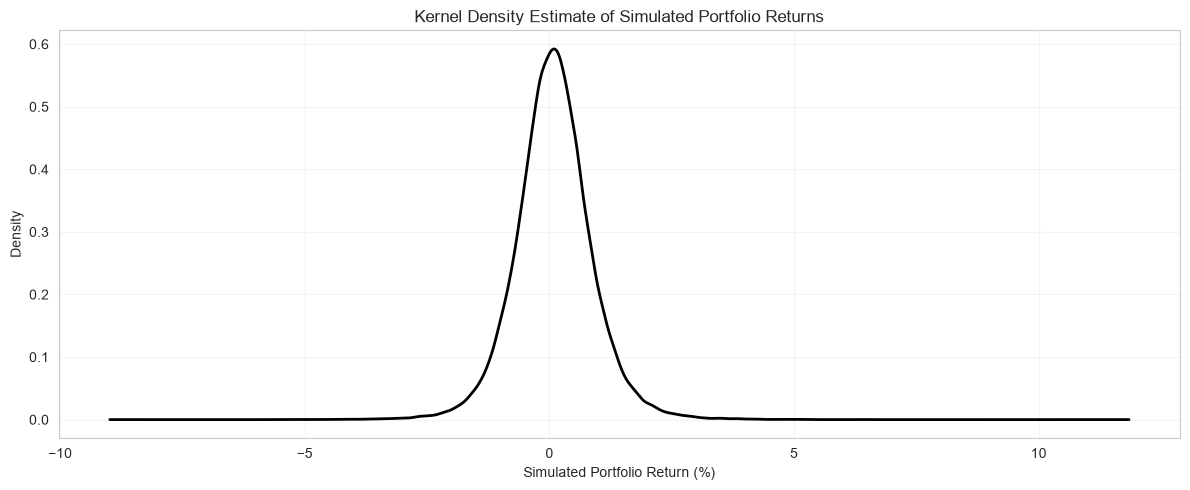

In [27]:
from scipy.stats import gaussian_kde

# KDE of simulated simple portfolio returns
kde = gaussian_kde(sim_port_returns)

x_kde = np.linspace(
    sim_port_returns.min(),
    sim_port_returns.max(),
    1000
)

y_kde = kde(x_kde)

plt.figure(figsize=(12, 5))

plt.plot(
    x_kde,
    y_kde,
    color="black",
    linewidth=2
)

plt.title("Kernel Density Estimate of Simulated Portfolio Returns")
plt.xlabel("Simulated Portfolio Return (%)")
plt.ylabel("Density")
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()


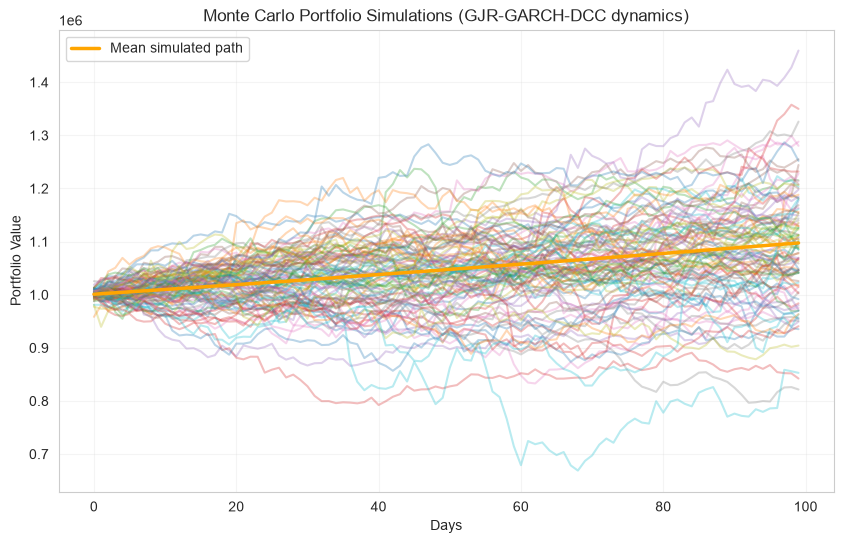

100-day VaR 95%: 78,465 (7.85%) | ES: 130,620
100-day VaR 99%: 161,121 (16.11%) | ES: 213,588


In [ ]:
horizon = HORIZON
n_paths = N_SIM
initial_value = PORTFOLIO_VALUE

# Initial state (time T) replicated for all paths
eps   = np.tile(eps_T, (n_paths, 1))
sig2  = np.tile(sig2_T, (n_paths, 1))
z_prev = np.tile(z_T, (n_paths, 1))
Q_prev = np.tile(Q_T, (n_paths, 1, 1))

simulated_paths = np.zeros((horizon, n_paths))
value = np.full(n_paths, float(initial_value))

for t in range(horizon):

    # GJR-GARCH variance update
    sig2 = omega_f + (alpha_f + gamma_f * (eps < 0)) * eps**2 + beta_f * sig2
    sig = np.sqrt(sig2)

    # DCC update
    Q_t = (
        (1 - a_hat - b_hat) * Qbar
        + a_hat * z_prev[:, :, None] * z_prev[:, None, :]
        + b_hat * Q_prev
    )
    d = 1.0 / np.sqrt(np.einsum("pii->pi", Q_t))
    R_t = Q_t * d[:, :, None] * d[:, None, :]

    # Correlated standardized shocks: z_t ~ N(0, R_t)
    Lc = np.linalg.cholesky(R_t)
    u = rng.standard_normal((n_paths, N))
    z_t = np.einsum("pij,pj->pi", Lc, u) * draw_scale(rng, (n_paths, 1), nu_mc)

    # Asset log returns (%) -> simple returns -> daily-rebalanced portfolio
    eps = sig * z_t
    r_log = mu_f + eps
    port_simple = np.expm1(r_log / 100) @ WEIGHTS

    value = value * (1 + port_simple)
    simulated_paths[t] = value

    z_prev, Q_prev = z_t, Q_t

# Mean simulated path
mean_path = simulated_paths.mean(axis=1)

plt.figure(figsize=(10, 6))

plt.plot(
    simulated_paths[:, :100],
    alpha=0.3
)

plt.plot(
    np.arange(horizon),
    mean_path,
    color="orange",
    linewidth=2.5,
    label="Mean simulated path"
)

plt.xlabel("Days")
plt.ylabel("Portfolio Value")
plt.title("Monte Carlo Portfolio Simulations (GJR-GARCH-DCC dynamics)")
plt.legend()
plt.grid(alpha=0.2)

plt.show()

# Horizon risk: loss distribution at the end of the horizon
pnl = simulated_paths[-1] - initial_value
for a in ALPHAS:
    q = np.quantile(pnl, a)
    print(f"{horizon}-day VaR {int((1-a)*100)}%: {-q:,.0f} "
          f"({-q / initial_value:.2%}) | ES: {-pnl[pnl <= q].mean():,.0f}")
